# Phase 1: EDA + toxic-bert Smoke Tests

Explore the Jigsaw 2018 toxic comment dataset and verify `unitary/toxic-bert` loads and runs.

**Data:** `data/raw/jigsaw/` (`train.csv`, `test.csv`, `test_labels.csv`)

In [2]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# Bootstrap src/ whether the kernel cwd is repo root or notebooks/
_cwd = Path.cwd()
_bootstrap = _cwd.parent if _cwd.name == "notebooks" else _cwd
sys.path.insert(0, str(_bootstrap / "src"))

from data import (
    add_toxic_any,
    comment_length_stats,
    label_cooccurrence,
    label_counts,
    load_test_df,
    load_train_df,
    verify_data_files,
)
from paths import LOCAL_MODEL_DIR, MODEL_ID, PROJECT_ROOT, SEED, TOXIC_LABELS

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Project root: {PROJECT_ROOT}")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Project root: C:\Users\theto\Documents\technion\11th_semester\deep\Project\DeepProjectHate
Device: cpu
PyTorch: 2.4.1


## 1. Data verification

In [3]:
verify_data_files()

train_df = load_train_df()
test_df = load_test_df()
train_df = add_toxic_any(train_df)
test_df = add_toxic_any(test_df)

print(f"Train rows: {len(train_df):,}")
print(f"Test rows (labeled): {len(test_df):,}")
print(f"Columns: {list(train_df.columns)}")
train_df.head(3)

Train rows: 159,571
Test rows (labeled): 63,978
Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'toxic_any']


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,toxic_any
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0


## 2. Label distribution (EDA)

,label,count,pct
0,toxic,15294,9.584448
1,severe_toxic,1595,0.999555
2,obscene,8449,5.294822
3,threat,478,0.299553
4,insult,7877,4.936361
5,identity_hate,1405,0.880486
6,toxic_any,16225,10.167888


C:\Users\theto\AppData\Local\Temp\ipykernel_30828\2950906126.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="label", y="pct", ax=ax, palette="viridis")


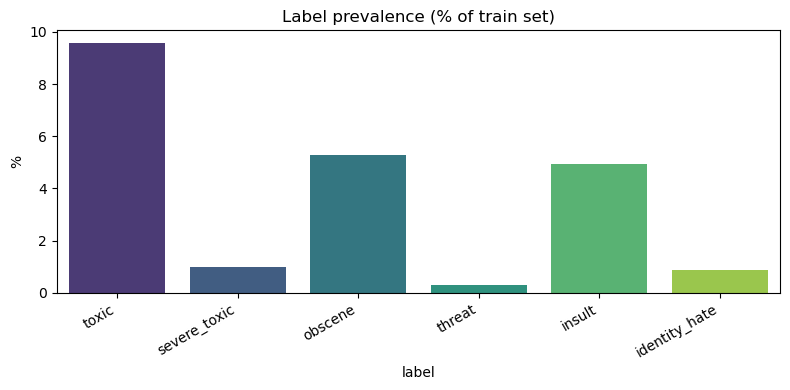

In [4]:
counts = label_counts(train_df)
display(counts)

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = counts[counts["label"] != "toxic_any"]
sns.barplot(data=plot_df, x="label", y="pct", ax=ax, palette="viridis")
ax.set_title("Label prevalence (% of train set)")
ax.set_ylabel("%")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Comment length distribution

,metric,value
0,chars_mean,394.073221
1,chars_median,205.000000
2,chars_max,5000.000000
3,words_mean,67.273527
4,words_median,36.000000
5,words_max,1411.000000


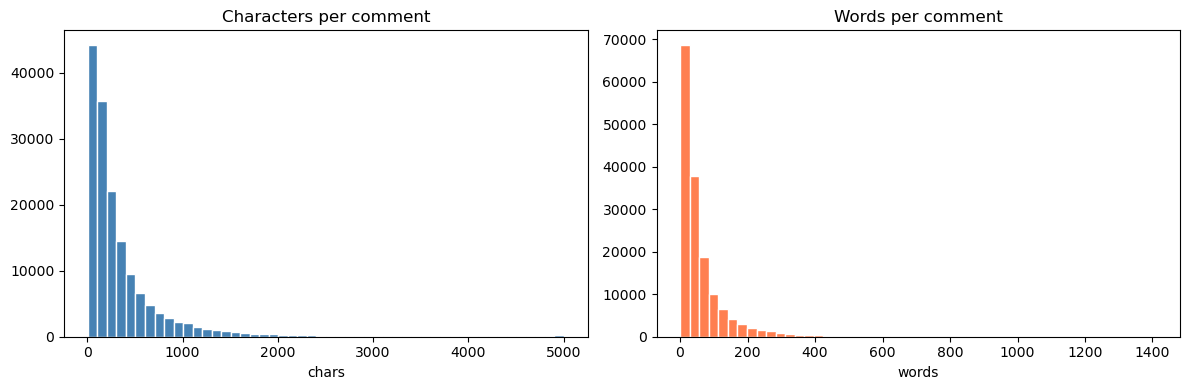

In [5]:
length_stats = comment_length_stats(train_df)
display(length_stats)

chars = train_df["comment_text"].astype(str).str.len()
words = train_df["comment_text"].astype(str).str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(chars, bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Characters per comment")
axes[0].set_xlabel("chars")
axes[1].hist(words, bins=50, color="coral", edgecolor="white")
axes[1].set_title("Words per comment")
axes[1].set_xlabel("words")
plt.tight_layout()
plt.show()

## 4. Label co-occurrence heatmap

Off-diagonal cells count comments where **both** labels are 1. The diagonal is each label's marginal count (label with itself) — not a cross-label pair — so we mask it with `NaN` for the plot.

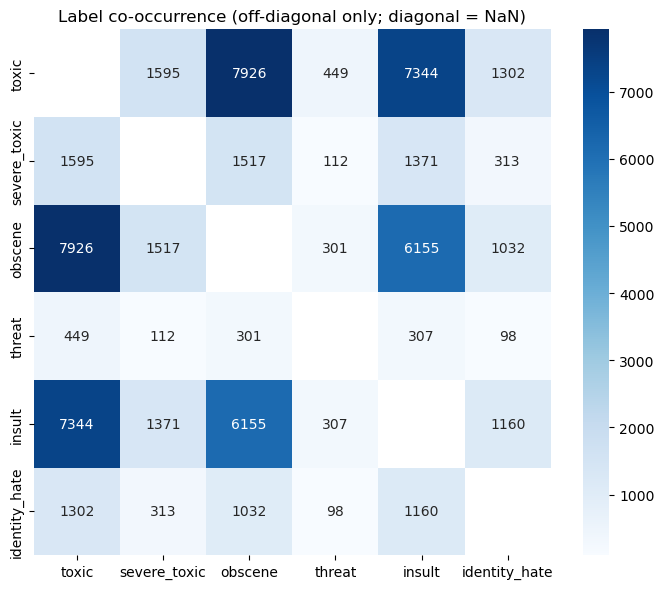

In [6]:
cooc = label_cooccurrence(train_df, mask_diagonal=True)
plt.figure(figsize=(7, 6))
sns.heatmap(cooc, annot=True, fmt=".0f", cmap="Blues", mask=cooc.isna())
plt.title("Label co-occurrence (off-diagonal only; diagonal = NaN)")
plt.tight_layout()
plt.show()

## 5. Example comments

In [7]:
def show_examples(df, label, toxic=True, n=2):
    subset = df[df[label] == (1 if toxic else 0)]
    for _, row in subset.sample(min(n, len(subset)), random_state=SEED).iterrows():
        print(f"[{label}={int(row[label])}] {row['comment_text'][:200]}")
        print("-" * 60)

print("=== Non-toxic examples ===")
show_examples(train_df, "toxic", toxic=False, n=3)

print("\n=== Toxic examples ===")
show_examples(train_df, "toxic", toxic=True, n=3)

print("\n=== identity_hate examples ===")
show_examples(train_df, "identity_hate", toxic=True, n=2)

=== Non-toxic examples ===
[toxic=0] "

 Tips about articles 

If you aren't certain if your article meets the policies and guidelines, you can always check Wikipedia:New contributors' help page and use Wikipedia:Article wizard. I would 
------------------------------------------------------------
[toxic=0] This is doubtful, as he has repeatedly in interviews denied that the Holocaust ever happened.
------------------------------------------------------------
[toxic=0] Hey man, not ONCE did i threaten anyone. I simply told the truth.
------------------------------------------------------------

=== Toxic examples ===
[toxic=1] HE WORSHIPPED SATAN AND SACRIFICED BABIES IN HIS NAME. MUSLIMS ARE TERRORISTS AND SHOULD BE SHOT. ALLAH DOESN'T EXIST.
------------------------------------------------------------
[toxic=1] wtf? 

so, youre twelve years old?? wow. wikipedia is my hero...  btw i attempted to add constructively to wikipedia, and it wasnt allowed. wikipedia has lost all my respect.


### Install model dependencies (run once)

If you get `ModuleNotFoundError: transformers`, run the next cell with this notebook's kernel (use `deep_learn`), then **Kernel → Restart** and run all cells from the top.

In [8]:
# Uncomment and run once if needed:
# %pip install -r ../requirements-project.txt

## 6. Load toxic-bert

Uses local copy in `models/toxic-bert/` if present, otherwise downloads from Hugging Face.

In [9]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_path = str(LOCAL_MODEL_DIR) if LOCAL_MODEL_DIR.exists() else MODEL_ID
print(f"Loading from: {model_path}")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")

Loading from: C:\Users\theto\Documents\technion\11th_semester\deep\Project\DeepProjectHate\models\toxic-bert
Parameters: 109,486,854


## 7. Smoke tests — hand-picked sentences

In [10]:
MAX_LENGTH = 256

def predict_toxic_scores(texts):
    """Return sigmoid probabilities for all 6 labels."""
    enc = tokenizer(
        list(texts), padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt"
    )
    enc = {k: v.to(device) for k, v in enc.items()}
    with torch.no_grad():
        logits = model(**enc).logits
        probs = torch.sigmoid(logits).cpu().numpy()
    return pd.DataFrame(probs, columns=TOXIC_LABELS, index=texts)

smoke_texts = [
    "You are an idiot and I hate you.",
    "Have a wonderful day, thank you for your help!",
    "I am Muslim and proud of my heritage.",
    "lol that was funny",
    "I will kill you",
]

smoke_df = predict_toxic_scores(smoke_texts)
smoke_df.round(3)

,toxic,severe_toxic,obscene,threat,insult,identity_hate
You are an idiot and I hate you.,0.992,0.042,0.719,0.002,0.952,0.015
"Have a wonderful day, thank you for your help!",0.001,0.000,0.000,0.000,0.000,0.000
I am Muslim and proud of my heritage.,0.001,0.000,0.000,0.000,0.000,0.000
lol that was funny,0.003,0.000,0.000,0.000,0.000,0.000
I will kill you,0.907,0.152,0.111,0.897,0.148,0.058


## 8. Smoke test — 100 balanced train comments (50 toxic / 50 non-toxic)

Random sampling would be ~90% non-toxic; we stratify so the sanity check in §9 has both classes.

In [11]:
n_each = 50
sample = pd.concat(
    [
        train_df[train_df["toxic"] == 1].sample(n_each, random_state=SEED),
        train_df[train_df["toxic"] == 0].sample(n_each, random_state=SEED),
    ]
).sample(frac=1, random_state=SEED).reset_index(drop=True)

sample_probs = predict_toxic_scores(sample["comment_text"].tolist())

print(f"Gold toxic rate in sample: {sample['toxic'].mean():.0%} ({sample['toxic'].sum()} / {len(sample)})")
print("Model P(toxic) distribution:")
display(sample_probs["toxic"].describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(sample_probs["toxic"], bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("All 100 comments")
axes[0].set_xlabel("P(toxic)")

for gold, color, label in [(0, "seagreen", "non-toxic"), (1, "indianred", "toxic")]:
    mask = (sample["toxic"] == gold).values
    axes[1].hist(
        sample_probs["toxic"].values[mask],
        bins=15,
        alpha=0.65,
        color=color,
        label=label,
        edgecolor="white",
    )
axes[1].set_title("By gold label")
axes[1].set_xlabel("P(toxic)")
axes[1].legend()

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

## 9. Sanity check — gold label vs model P(toxic)

Visual check that scores separate the two classes and spot disagreements (FP/FN).

Agreement on 100 balanced samples (threshold=0.5): 95.0%
(Quick sanity check — not final eval on a held-out split)
quadrant
FN     3
FP     2
TN    48
TP    47


C:\Users\theto\AppData\Local\Temp\ipykernel_32548\2503199107.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


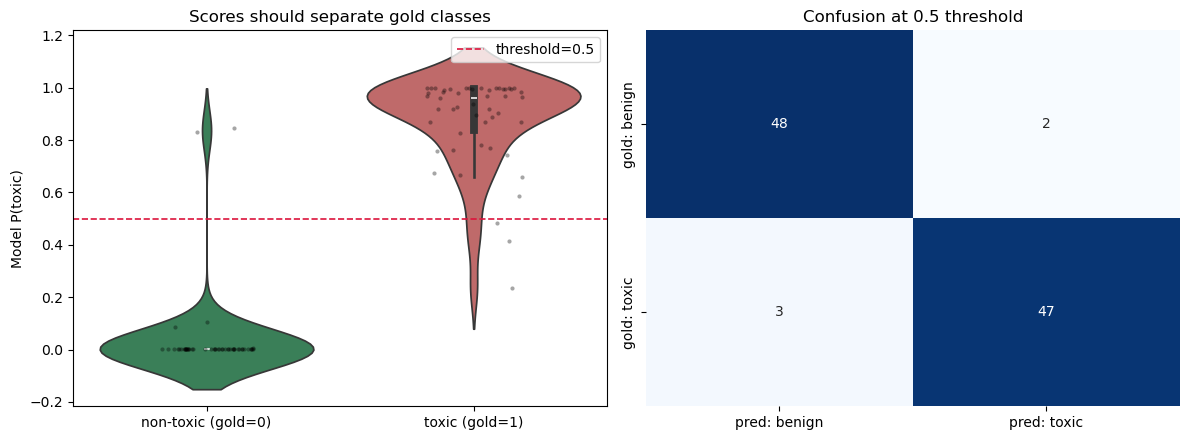


Representative examples (up to 2 per quadrant):


,quadrant,type,gold_toxic,model_p_toxic,comment
0,TP,True positive,1,0.999,NJGW IS AN UNEMPLOYED MOTHER FUCKING BASTARD L...
1,TP,True positive,1,0.998,You fucked the dog on this one clown
2,TN,True negative,0,0.001,""" Thank you very much for doing that, very ki..."
3,TN,True negative,0,0.001,""" The statements have to be clear - there must..."
4,FP,False positive,0,0.846,""" Too funny corey suggests a famous people s..."
5,FP,False positive,0,0.829,Wil Wheaton Wil Wheaton loves star wars you jerk
6,FN,False negative,1,0.235,""" Oregon Vortex Hello Queen Cake! Your c..."
7,FN,False negative,1,0.415,""":::: You are an unprofessional editor. You ma..."


In [ ]:
THRESHOLD = 0.5

compare = sample[["comment_text", "toxic"]].copy()
compare["model_p_toxic"] = sample_probs["toxic"].values
compare["model_pred_toxic"] = (compare["model_p_toxic"] >= THRESHOLD).astype(int)
compare["quadrant"] = np.select(
    [
        (compare["toxic"] == 1) & (compare["model_pred_toxic"] == 1),
        (compare["toxic"] == 0) & (compare["model_pred_toxic"] == 0),
        (compare["toxic"] == 0) & (compare["model_pred_toxic"] == 1),
        (compare["toxic"] == 1) & (compare["model_pred_toxic"] == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="?",
)

agreement = (compare["toxic"] == compare["model_pred_toxic"]).mean()
print(f"Agreement on {len(compare)} balanced samples (threshold={THRESHOLD}): {agreement:.1%}")
print("(Quick sanity check — not final eval on a held-out split)")
print(compare["quadrant"].value_counts().sort_index().to_string())

plot_df = compare.assign(
    gold_label=compare["toxic"].map({0: "non-toxic (gold=0)", 1: "toxic (gold=1)"})
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
sns.violinplot(
    data=plot_df, x="gold_label", y="model_p_toxic", ax=ax, inner="box", palette=["seagreen", "indianred"]
)
sns.stripplot(
    data=plot_df,
    x="gold_label",
    y="model_p_toxic",
    ax=ax,
    color="black",
    alpha=0.35,
    size=3,
    jitter=0.18,
)
ax.axhline(THRESHOLD, color="crimson", linestyle="--", linewidth=1.2, label=f"threshold={THRESHOLD}")
ax.set_ylabel("Model P(toxic)")
ax.set_xlabel("")
ax.set_title("Scores should separate gold classes")
ax.legend(loc="upper right")

cm = pd.crosstab(compare["toxic"], compare["model_pred_toxic"])
cm.index = ["gold: benign", "gold: toxic"]
cm.columns = ["pred: benign", "pred: toxic"]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Confusion at 0.5 threshold")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


def _truncate(text, n=120):
    text = str(text).replace("\n", " ")
    return text if len(text) <= n else text[: n - 3] + "..."


quadrant_info = {
    "TP": ("True positive", lambda df: df.nlargest(2, "model_p_toxic")),
    "TN": ("True negative", lambda df: df.nsmallest(2, "model_p_toxic")),
    "FP": ("False positive", lambda df: df.nlargest(2, "model_p_toxic")),
    "FN": ("False negative", lambda df: df.nsmallest(2, "model_p_toxic")),
}

example_rows = []
for code, (name, picker) in quadrant_info.items():
    sub = compare[compare["quadrant"] == code]
    if sub.empty:
        example_rows.append(
            {
                "quadrant": code,
                "type": name,
                "gold_toxic": None,
                "model_p_toxic": None,
                "comment": "(none in this sample)",
            }
        )
        continue
    for _, row in picker(sub).iterrows():
        example_rows.append(
            {
                "quadrant": code,
                "type": name,
                "gold_toxic": int(row["toxic"]),
                "model_p_toxic": round(row["model_p_toxic"], 3),
                "comment": _truncate(row["comment_text"]),
            }
        )

examples_df = pd.DataFrame(example_rows)
print("\nRepresentative examples (up to 2 per quadrant):")
display(examples_df)

## 10. Length vs toxicity + truncation audit

Check whether toxic comments differ in length and how often `max_length` truncates inputs.

Token indices sequence length is longer than the specified maximum sequence length for this model (519 > 512). Running this sequence through the model will result in indexing errors


Truncation at max_length=256: 6.66% of 10,000 sampled comments


C:\Users\theto\AppData\Local\Temp\ipykernel_32548\1831730505.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_plot, x="gold", y="word_count", ax=axes[0], palette=["seagreen", "indianred"])


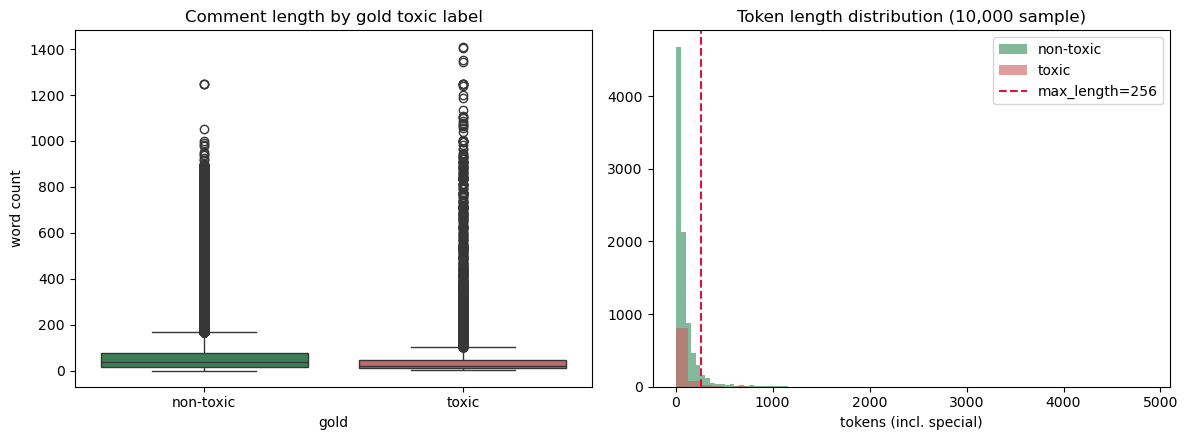

In [ ]:
train_plot = train_df.assign(
    word_count=train_df["comment_text"].astype(str).str.split().str.len(),
    gold=train_df["toxic"].map({0: "non-toxic", 1: "toxic"}),
)

audit_n = min(10_000, len(train_df))
audit_df = train_df.sample(audit_n, random_state=SEED)
enc_no_trunc = tokenizer(
    audit_df["comment_text"].astype(str).tolist(),
    truncation=False,
    add_special_tokens=True,
)
token_lens = np.array([len(ids) for ids in enc_no_trunc["input_ids"]])
audit_df = audit_df.assign(token_len=token_lens, truncated=token_lens > MAX_LENGTH)

trunc_pct = 100 * audit_df["truncated"].mean()
print(f"Truncation at max_length={MAX_LENGTH}: {trunc_pct:.2f}% of {audit_n:,} sampled comments")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=train_plot, x="gold", y="word_count", ax=axes[0], palette=["seagreen", "indianred"])
axes[0].set_title("Comment length by gold toxic label")
axes[0].set_ylabel("word count")

axes[1].hist(
    audit_df.loc[audit_df["toxic"] == 0, "token_len"],
    bins=40,
    alpha=0.6,
    label="non-toxic",
    color="seagreen",
)
axes[1].hist(
    audit_df.loc[audit_df["toxic"] == 1, "token_len"],
    bins=40,
    alpha=0.6,
    label="toxic",
    color="indianred",
)
axes[1].axvline(MAX_LENGTH, color="crimson", linestyle="--", label=f"max_length={MAX_LENGTH}")
axes[1].set_xlabel("tokens (incl. special)")
axes[1].set_title(f"Token length distribution ({audit_n:,} sample)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 11. Inference micro-benchmark (toxic-bert)

Latency disclosure for fair comparison later (params + ms/sample on this hardware).

In [ ]:
import time

def benchmark_inference(texts, batch_size=8, warmup=2):
    texts = list(texts)
    for _ in range(warmup):
        for i in range(0, len(texts), batch_size):
            predict_toxic_scores(texts[i : i + batch_size])
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i in range(0, len(texts), batch_size):
        predict_toxic_scores(texts[i : i + batch_size])
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return 1000 * elapsed / len(texts)


bench_texts = sample["comment_text"].tolist()  # repeat balanced sample for stable timing

print(f"Model: {MODEL_ID}")
print(f"Parameters: {n_params:,}")
print(f"Device: {device}")
print(f"max_length: {MAX_LENGTH}")
print(f"Benchmark: {len(bench_texts):,} comments\n")

for bs in [1, 8, 32]:
    ms = benchmark_inference(bench_texts, batch_size=bs)
    print(f"  batch_size={bs:2d} -> {ms:.2f} ms/sample")

Model: unitary/toxic-bert
Parameters: 109,486,854
Device: cpu
max_length: 256
Benchmark: 100 comments

  batch_size= 1 -> 202.86 ms/sample


KeyboardInterrupt: 

## 12. Quick baseline — TF-IDF + LinearSVM

Trained on a 5k stratified subset; evaluated on the same balanced 100 comments from §8–9. **Not** the final E0 benchmark.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.svm import LinearSVC

BASELINE_N = 5000
baseline_train = pd.concat(
    [
        train_df[train_df["toxic"] == 1].sample(BASELINE_N // 2, random_state=SEED),
        train_df[train_df["toxic"] == 0].sample(BASELINE_N // 2, random_state=SEED),
    ]
)

vec = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), min_df=2)
X_train = vec.fit_transform(baseline_train["comment_text"].astype(str))
y_train = baseline_train["toxic"].values

svm = LinearSVC(max_iter=2000, random_state=SEED)
svm.fit(X_train, y_train)

X_eval = vec.transform(compare["comment_text"].astype(str))
compare_eval = compare.copy()
compare_eval["svm_pred"] = svm.predict(X_eval)

svm_agree = (compare_eval["toxic"] == compare_eval["svm_pred"]).mean()
bert_agree = (compare_eval["toxic"] == compare_eval["model_pred_toxic"]).mean()

print("TF-IDF + LinearSVC (trained on 5k stratified subset)")
print(f"Agreement vs gold on {len(compare_eval)} balanced eval comments:")
print(f"  SVM:        {svm_agree:.1%}")
print(f"  toxic-bert: {bert_agree:.1%}")
print("(Quick sanity baseline — not final E0 benchmark)\n")
print(classification_report(compare_eval["toxic"], compare_eval["svm_pred"], target_names=["benign", "toxic"]))

TF-IDF + LinearSVC (trained on 5k stratified subset)
Agreement vs gold on 100 balanced eval comments:
  SVM:        100.0%
  toxic-bert: 95.0%
(Quick sanity baseline — not final E0 benchmark)

              precision    recall  f1-score   support

      benign       1.00      1.00      1.00        50
       toxic       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



c:\Users\theto\anaconda3\envs\deep_learn\lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


## Next steps

- **Next:** Primary exploration for DistilGPT-2 (decoder prompting) — mirror this notebook's smoke-test pattern
- Deferred: formal eval notebook — train/val/test split (`data/processed/split.pt`) + held-out metrics
- Phase 2: `run_benchmark.py` for full encoder/decoder matrix under fair comparison rules
- Perturbation suite and per-identity FPR (Jigsaw 2019 or synthetic templates)
- Distillation: toxic-bert → DistilBERT